# Predicting first-stage landing

Grid search for four classifiers, then a stress test across many random splits.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
Y = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")["Class"].to_numpy()
raw = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv")
X = StandardScaler().fit_transform(raw)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print(X.shape, X_train.shape, X_test.shape, "test landings:", Y_test.sum())

(90, 83) (72, 83) (18, 83) test landings: 12


In [2]:
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), {"C": [0.01, 0.1, 1], "solver": ["lbfgs"]}),
    "SVM": (SVC(), {"kernel": ["linear", "rbf", "poly", "sigmoid"], "C": np.logspace(-3, 3, 5), "gamma": np.logspace(-3, 3, 5)}),
    "Decision Tree": (DecisionTreeClassifier(random_state=2), {"criterion": ["gini", "entropy"], "splitter": ["best", "random"],
                      "max_depth": list(range(2, 20, 2)), "max_features": ["sqrt"], "min_samples_leaf": [1, 2, 4], "min_samples_split": [2, 5, 10]}),
    "KNN": (KNeighborsClassifier(), {"n_neighbors": list(range(1, 11)), "algorithm": ["auto", "ball_tree", "kd_tree", "brute"], "p": [1, 2]}),
}
fitted, rows = {}, []
for name, (model, params) in grids.items():
    fitted[name] = GridSearchCV(model, params, cv=10).fit(X_train, Y_train)
    rows.append({"Model": name, "CV accuracy": fitted[name].best_score_, "Test accuracy": fitted[name].score(X_test, Y_test),
                 "Best parameters": str(fitted[name].best_params_)})
results = pd.DataFrame(rows)
results.to_csv("model_results.csv", index=False)
pd.set_option("display.max_colwidth", None)
results

,Model,CV accuracy,Test accuracy,Best parameters
0,Logistic Regression,0.846429,0.833333,"{'C': 0.01, 'solver': 'lbfgs'}"
1,SVM,0.848214,0.833333,"{'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}"
2,Decision Tree,0.876786,0.833333,"{'criterion': 'gini', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'splitter': 'best'}"
3,KNN,0.848214,0.833333,"{'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}"


Decision Tree [[3, 3], [0, 12]] baseline test accuracy: 0.6666666666666666


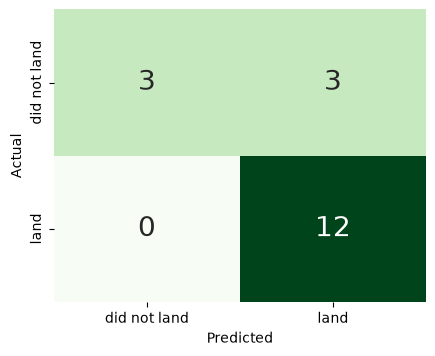

In [3]:
best = results.sort_values("CV accuracy", ascending=False).iloc[0]["Model"]
cm = confusion_matrix(Y_test, fitted[best].predict(X_test))
print(best, cm.tolist(), "baseline test accuracy:", max(Y_test.mean(), 1 - Y_test.mean()))
fig, ax = plt.subplots(figsize=(4.8, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, annot_kws={"size": 20}, ax=ax,
            xticklabels=["did not land", "land"], yticklabels=["did not land", "land"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
fig.savefig("images/confusion_matrix.png", dpi=170, bbox_inches="tight")
plt.show()

In [4]:
def stress(data, n=100):
    out = {}
    splits = list(StratifiedShuffleSplit(n_splits=n, test_size=0.2, random_state=0).split(data, Y))
    models = {"Baseline": DummyClassifier(strategy="most_frequent")}
    for name in fitted:
        params = {k: v for k, v in fitted[name].best_params_.items()}
        models[name] = type(grids[name][0])(**params, **({"max_iter": 1000} if name == "Logistic Regression" else {}))
    for name, model in models.items():
        pipe = make_pipeline(StandardScaler(), model)
        out[name] = [pipe.fit(data.iloc[a], Y[a]).score(data.iloc[b], Y[b]) for a, b in splits]
    return pd.DataFrame(out)


pad = [c for c in raw.columns if c.startswith("LandingPad_")]
serial = [c for c in raw.columns if c.startswith("Serial_")]
full = stress(raw)
no_pad = stress(raw.drop(columns=pad))
summary = pd.DataFrame({"mean all features": full.mean(), "p5": full.quantile(.05), "p95": full.quantile(.95), "mean without LandingPad": no_pad.mean()})
summary.to_csv("stress_test.csv")
print(len(pad), len(serial))
summary.round(3)

5 53


,mean all features,p5,p95,mean without LandingPad
Baseline,0.667,0.667,0.667,0.667
Logistic Regression,0.838,0.722,0.944,0.839
SVM,0.847,0.722,0.944,0.833
Decision Tree,0.811,0.667,0.944,0.817
KNN,0.847,0.722,0.944,0.846
